## Chủ đề số 14: Bank marketing
## Bài toán: Dự đoán khách hàng có đăng ký gửi tiền kỳ hạn hay không (Yes/No) 
## Loại bài toán: Classification

### Tập dữ liệu: UCI Bank Marketing (https://archive.ics.uci.edu/dataset/222/bank+marketing)
### Sử dụng 4 thuật toán: Logistic Regression, KNN, Decision Tree, RandomForest
### Độ đo: F1, Recall, ROC-AUC

### 1. Đọc dữ liệu

In [10]:
import pandas as pd

df = pd.read_csv("data/bank-additional.csv", sep=";")
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,30,blue-collar,married,basic.9y,no,yes,no,cellular,may,fri,...,2,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
1,39,services,single,high.school,no,no,no,telephone,may,fri,...,4,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
2,25,services,married,high.school,no,yes,no,telephone,jun,wed,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.962,5228.1,no
3,38,services,married,basic.9y,no,unknown,unknown,telephone,jun,fri,...,3,999,0,nonexistent,1.4,94.465,-41.8,4.959,5228.1,no
4,47,admin.,married,university.degree,no,yes,no,cellular,nov,mon,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.191,5195.8,no


### 2. Khám phá dữ liệu EDA

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Đọc dữ liệu
df = pd.read_csv(
    "data/bank-additional-full.csv",
    sep=";"
)

# Hiển thị 5 dòng đầu tiên
display(df.head())

# Kích thước dữ liệu
print("Số dòng:", df.shape[0])
print("Số cột:", df.shape[1])

# Thông tin dữ liệu
df.info()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


Số dòng: 41188
Số cột: 21
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   

y
no     36548
yes     4640
Name: count, dtype: int64
y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64


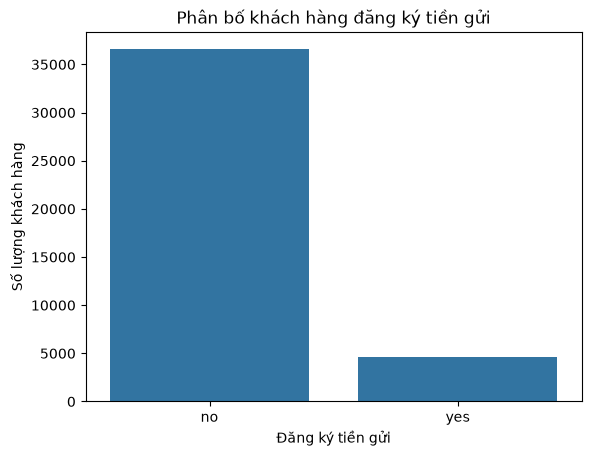

In [12]:
print(df["y"].value_counts())
print(df["y"].value_counts(normalize=True) * 100)

sns.countplot(data=df, x="y")
plt.title("Phân bố khách hàng đăng ký tiền gửi")
plt.xlabel("Đăng ký tiền gửi")
plt.ylabel("Số lượng khách hàng")
plt.show()

### 3. Tiền xử lý dữ liệu

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Giữ "unknown" như một nhóm riêng; loại bản ghi trùng và thiếu nhãn.
df_model = df.drop_duplicates().dropna(subset=["y"]).copy()

# duration chỉ biết sau cuộc gọi, không dùng để dự đoán trước cuộc gọi.
X = df_model.drop(columns=["y", "duration"])
y = df_model["y"].map({"no": 0, "yes": 1})

numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
    ]
)

# Chỉ fit trên train để tránh rò rỉ thông tin từ tập test.
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)
feature_names = preprocessor.get_feature_names_out()

print(f"Số dòng sau khi loại trùng/thiếu nhãn: {len(df_model)}")
print(f"Số đặc trưng sau mã hóa: {len(feature_names)}")
print(f"Train: X={X_train.shape}, y={y_train.shape}")
print(f"Test:  X={X_test.shape}, y={y_test.shape}")
print("Tỷ lệ nhãn trong train (%):")
print(y_train.map({0: "no", 1: "yes"}).value_counts(normalize=True).mul(100).round(2))

Số dòng sau khi loại trùng/thiếu nhãn: 41176
Số đặc trưng sau mã hóa: 62
Train: X=(32940, 62), y=(32940,)
Test:  X=(8236, 62), y=(8236,)
Tỷ lệ nhãn trong train (%):
y
no     88.73
yes    11.27
Name: proportion, dtype: float64


### 4. Thuật toán Logistic Regression

In [12]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Bước 1: Khởi tạo mô hình
lr_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

# Bước 2: Huấn luyện mô hình
lr_model.fit(X_train, y_train)

# Bước 3: Dự đoán trên tập kiểm tra
y_pred_lr = lr_model.predict(X_test)

# Lấy xác suất của lớp đăng ký "yes"
# Cách này áp dụng khi nhãn y là 0/1 hoặc False/True
classes = list(lr_model.classes_)
yes_index = classes.index(1) if 1 in classes else classes.index("yes")
y_prob_lr = lr_model.predict_proba(X_test)[:, yes_index]

# Bước 4: Đánh giá mô hình
print("===== LOGISTIC REGRESSION =====")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lr, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_lr, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_lr, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob_lr):.4f}")

# Báo cáo chi tiết
print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(y_test, y_pred_lr, zero_division=0))

# Bước 5: Ma trận nhầm lẫn (không cần Matplotlib)
print("===== CONFUSION MATRIX =====")
print(confusion_matrix(y_test, y_pred_lr))

# Bước 6: Lưu kết quả để so sánh các mô hình
lr_result = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred_lr),
    "Precision": precision_score(y_test, y_pred_lr, zero_division=0),
    "Recall": recall_score(y_test, y_pred_lr, zero_division=0),
    "F1-score": f1_score(y_test, y_pred_lr, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob_lr)
}

print("\nĐã lưu kết quả vào biến lr_result.")


===== LOGISTIC REGRESSION =====
Accuracy:  0.8337
Precision: 0.3423
Recall:    0.5667
F1-score:  0.4268
ROC-AUC:   0.7599

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

           0       0.94      0.87      0.90       734
           1       0.34      0.57      0.43        90

    accuracy                           0.83       824
   macro avg       0.64      0.72      0.66       824
weighted avg       0.88      0.83      0.85       824

===== CONFUSION MATRIX =====
[[636  98]
 [ 39  51]]

Đã lưu kết quả vào biến lr_result.


### 5. KNN
#### 5.1.Giới thiệu 
K-Nearest Neighbors (KNN) là thuật toán học máy có giám sát, được sử dụng trong các bài toán phân loại và hồi quy.

Đối với bài toán Bank Marketing, KNN dự đoán khách hàng có đăng ký tiền gửi kỳ hạn hay không dựa trên nhãn của K khách hàng gần nhất trong không gian đặc trưng.

Trong thực nghiệm baseline, mô hình sử dụng K = 5 và khoảng cách Euclidean.

In [14]:
from sklearn.neighbors import KNeighborsClassifier

# Khởi tạo mô hình KNN baseline
knn = KNeighborsClassifier(
    n_neighbors=5,
    metric="euclidean"
)

# Huấn luyện mô hình
knn.fit(X_train, y_train)

print("Đã huấn luyện KNN baseline thành công!")

Đã huấn luyện KNN baseline thành công!


#### 5.2. Dự đoán kết quả

Sau khi huấn luyện, mô hình KNN được sử dụng để dự đoán khả năng đăng ký tiền gửi kỳ hạn của khách hàng trên tập kiểm tra.

Nhãn 0 biểu thị khách hàng không đăng ký, trong khi nhãn 1 biểu thị khách hàng có đăng ký.

In [15]:
# Dự đoán nhãn
y_pred_knn = knn.predict(X_test)

# Xác suất dự đoán lớp 1
y_prob_knn = knn.predict_proba(X_test)[:, 1]

print("10 kết quả dự đoán đầu tiên:")
print(y_pred_knn[:10])

10 kết quả dự đoán đầu tiên:
[0 1 0 0 0 0 0 0 0 0]


#### 5.3. Đánh giá mô hình KNN

Đánh giá hiệu suất mô hình KNN thông qua các chỉ số Accuracy, Precision, Recall, F1-score và ROC-AUC.

In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred_knn)
precision = precision_score(y_test, y_pred_knn, zero_division=0)
recall = recall_score(y_test, y_pred_knn, zero_division=0)
f1 = f1_score(y_test, y_pred_knn, zero_division=0)
auc = roc_auc_score(y_test, y_prob_knn)

print("KẾT QUẢ KNN BASELINE")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_knn,
    target_names=["No", "Yes"],
    zero_division=0
))

KẾT QUẢ KNN BASELINE
Accuracy : 0.8955
Precision: 0.5661
Recall   : 0.3093
F1-score : 0.4000
ROC-AUC  : 0.7404

Classification Report:
              precision    recall  f1-score   support

          No       0.92      0.97      0.94      7308
         Yes       0.57      0.31      0.40       928

    accuracy                           0.90      8236
   macro avg       0.74      0.64      0.67      8236
weighted avg       0.88      0.90      0.88      8236



#### Confusion Matrix

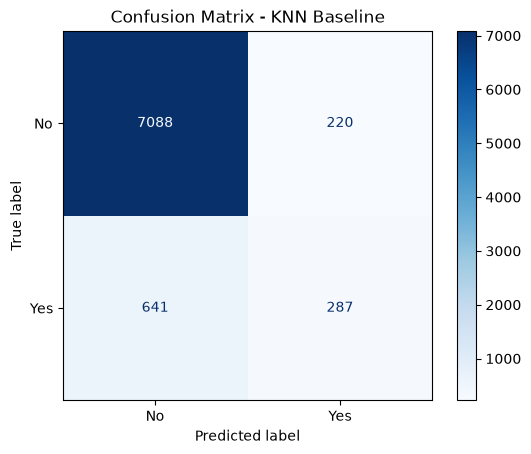

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_knn,
    display_labels=["No", "Yes"],
    cmap="Blues"
)

plt.title("Confusion Matrix - KNN Baseline")
plt.show()

#### ROC Curve

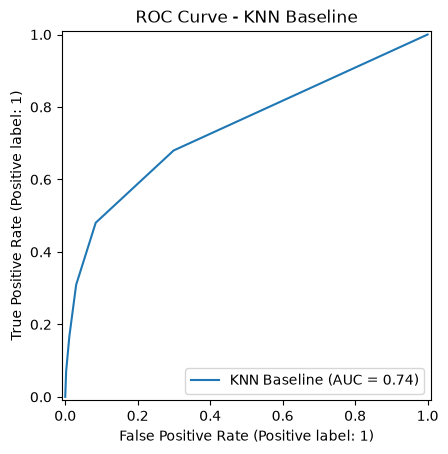

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_knn,
    name="KNN Baseline"
)

plt.title("ROC Curve - KNN Baseline")
plt.show()

### 6. Thuật toán Decision Tree

### 7. Thuật toán RandomForest
#### 7.1. Giới thiệu

RandomForest là thuật toán học có giám sát, kết hợp nhiều cây quyết định để phân loại khách hàng có đăng ký tiền gửi kỳ hạn hay không.

Mô hình sử dụng 300 cây và `class_weight="balanced"` để hỗ trợ xử lý dữ liệu có tỉ lệ nhãn không cân bằng.

In [23]:
from sklearn.ensemble import RandomForestClassifier

# Khởi tạo mô hình RandomForest baseline
random_forest = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)

# Huấn luyện mô hình
random_forest.fit(X_train, y_train)

print("Đã huấn luyện RandomForest baseline thành công!")

Đã huấn luyện RandomForest baseline thành công!


#### 7.2. Dự đoán kết quả

Sau khi huấn luyện, mô hình RandomForest dự đoán nhãn và xác suất đăng ký tiền gửi kỳ hạn trên tập kiểm tra.

In [24]:
y_pred_rf = random_forest.predict(X_test)
y_proba_rf = random_forest.predict_proba(X_test)[:, 1]

print("Đã dự đoán trên tập kiểm tra!")

Đã dự đoán trên tập kiểm tra!


#### 7.3. Đánh giá mô hình RandomForest

Đánh giá mô hình bằng ba độ đo đã chọn: F1-score, Recall và ROC-AUC.

In [21]:
from sklearn.metrics import f1_score, recall_score, roc_auc_score

f1_rf = f1_score(y_test, y_pred_rf, zero_division=0)
recall_rf = recall_score(y_test, y_pred_rf, zero_division=0)
roc_auc_rf = roc_auc_score(y_test, y_proba_rf)

print("Kết quả RANDOMFOREST BASELINE")
print(f"F1-score: {f1_rf:.4f}")
print(f"Recall   : {recall_rf:.4f}")
print(f"ROC-AUC  : {roc_auc_rf:.4f}")

Kết quả RANDOMFOREST BASELINE
F1-score: 0.2655
Recall   : 0.1667
ROC-AUC  : 0.7498


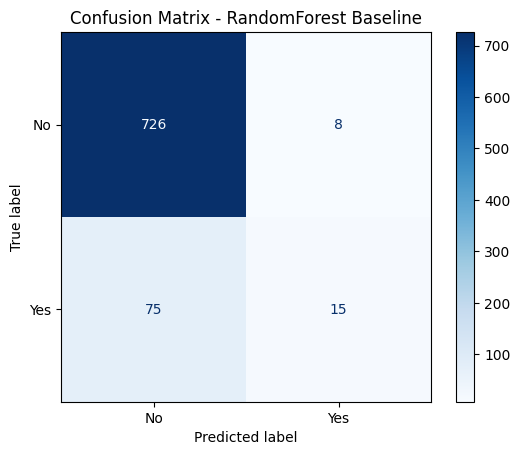

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=["No", "Yes"],
    cmap="Blues",
)
plt.title("Confusion Matrix - RandomForest Baseline")
plt.show()

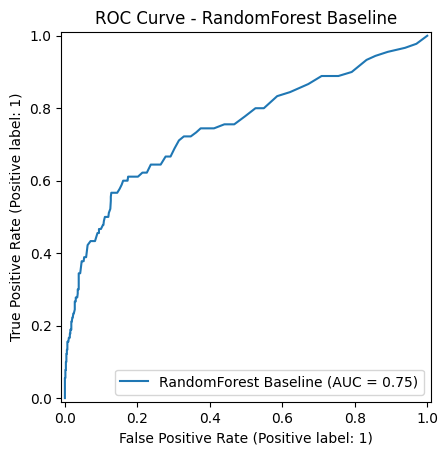

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    y_proba_rf,
    name="RandomForest Baseline",
)
plt.title("ROC Curve - RandomForest Baseline")
plt.show()

Top 10 đặc trưng quan trọng nhất:
num__euribor3m         0.1271
num__age               0.1015
num__nr.employed       0.0658
num__campaign          0.0589
num__emp.var.rate      0.0467
num__cons.conf.idx     0.0388
num__cons.price.idx    0.0313
num__pdays             0.0234
cat__job_admin.        0.0192
cat__housing_no        0.0178
dtype: float64


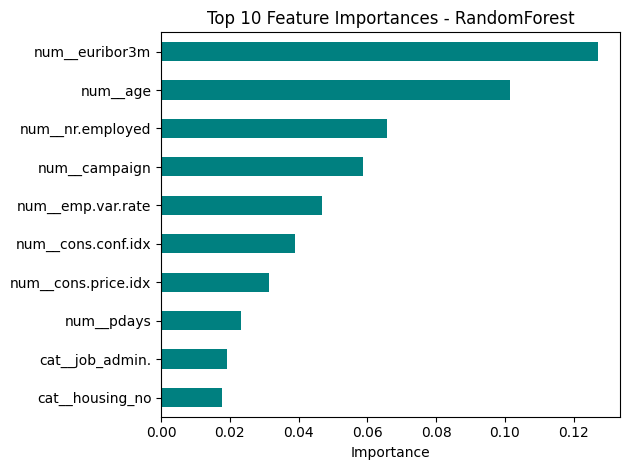

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
importance_rf = pd.Series(
    random_forest.feature_importances_,
    index=feature_names,
)
print("Top 10 đặc trưng quan trọng nhất:")
print(importance_rf.sort_values(ascending=False).head(10).round(4))

importance_rf.sort_values().tail(10).plot(kind="barh", color="teal")
plt.title("Top 10 Feature Importances - RandomForest")
plt.xlabel("Importance")
plt.ylabel("")
plt.tight_layout()
plt.show()

### 8. So sánh kết quả các mô hình 
